In [1]:
# Cell 1: Optimized imports and memory settings
import numpy as np
from scipy.io import loadmat
import ssm
import time
import json
import warnings
import matplotlib.pyplot as plt
import os
import gc

# Memory optimization: limit threads
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'

%matplotlib inline
warnings.filterwarnings('ignore')

print("✓ Imports complete")
print(f"Threads limited to: {os.environ.get('OMP_NUM_THREADS')}")

c:\Users\LENOVO\python\envs\onamllm\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Imports complete
Threads limited to: 2


In [2]:
# Cell 2: Utility functions with memory optimization
def fit_rslds_until_converged(data_T, K, D_latent, seed, max_iters=200, check_every=10, threshold=10, inputs=None):
    """Fit rSLDS model until convergence with memory optimization"""
    np.random.seed(seed)
    start_time = time.time()
    
    # Use float32 to save memory (half the size)
    data_T = data_T.astype(np.float32)
    
    model = ssm.SLDS(
        data_T.shape[1], K, D_latent,
        transitions="recurrent_only",
        dynamics="diagonal_gaussian",
        emissions="gaussian_orthog",
        single_subspace=True
    )
    
    model.initialize(data_T)
    all_elbos = []
    converged = False
    total_iters = 0
    
    while total_iters < max_iters:
        elbos_chunk, posterior = model.fit(
            data_T,
            method="laplace_em",
            variational_posterior="structured_meanfield",
            num_iters=check_every,
            initialize=False,
            inputs=inputs
        )
        all_elbos.extend(elbos_chunk)
        total_iters += check_every
        
        if len(all_elbos) >= check_every:
            change = abs(all_elbos[-1] - all_elbos[-check_every])
            if change < threshold:
                converged = True
                break
        
        # Aggressive garbage collection
        if total_iters % 20 == 0:
            gc.collect()
    
    continuous_states = posterior.mean_continuous_states[0]
    discrete_probs = posterior.mean_discrete_states[0]
    discrete_states = np.argmax(discrete_probs, axis=1)
    
    return model, discrete_states, continuous_states, all_elbos, time.time() - start_time, converged, total_iters

def variance_explained(model, continuous_states):
    """Compute variance explained - memory efficient"""
    C = model.emissions.Cs[0].astype(np.float32)
    log_noise_var = model.emissions.inv_etas[0].astype(np.float32)
    noise_var = np.exp(log_noise_var)
    
    T, D = continuous_states.shape
    x_centered = continuous_states - continuous_states.mean(axis=0)
    cov_x = (x_centered.T @ x_centered) / (T - 1)
    latent_var = np.diag(cov_x)
    
    latent_contribution = np.sum(C ** 2 * latent_var[None, :], axis=1)
    total_var = latent_contribution + noise_var
    
    total_latent_var = np.sum(latent_var)
    total_noise_var = np.sum(noise_var)
    var_exp_global = total_latent_var / (total_latent_var + total_noise_var + 1e-10)
    var_exp_per_latent = latent_var / (np.sum(latent_var) + 1e-10)
    
    return var_exp_per_latent, var_exp_global

print("✓ Functions defined (memory optimized)")

✓ Functions defined (memory optimized)


In [3]:
# Cell 3: Load full data efficiently
print("Loading full data...")
print(f"Available RAM before load: {__import__('psutil').virtual_memory().available / 1024**3:.1f} GB")

data_path = r'C:\Users\LENOVO\OneDrive\Documents\URECA_codes\data\rawdata_combined.mat'

# Load only what we need
mat_raw = loadmat(data_path)
mpo = mat_raw['MPO_cno']
struct0 = mpo[0, 0][0, 0]
trace = struct0['trace'].astype(np.float32)  # Convert to float32 immediately
label = struct0['label'].flatten()

print(f"Full data: {trace.shape}")
print(f"Memory after load: {__import__('psutil').Process().memory_info().rss / 1024**3:.2f} GB")

# Extract first aggression bout
bs = 31106
be = 31986
start_idx = bs - 500
end_idx = be + 500

window_data = trace[start_idx:end_idx, :].copy()  # Make a copy
window_labels = label[start_idx:end_idx].copy()

# Clear original data immediately
del mat_raw, mpo, struct0, trace, label
gc.collect()

print(f"Window data shape: {window_data.shape} (FULL 103 neurons)")
print(f"Memory after extraction: {__import__('psutil').Process().memory_info().rss / 1024**3:.2f} GB")

Loading full data...
Available RAM before load: 1.2 GB
Full data: (58845, 103)
Memory after load: 3.18 GB
Window data shape: (1880, 103) (FULL 103 neurons)
Memory after extraction: 0.15 GB


In [4]:
# Cell 4: Z-score normalize
print("Normalizing full data...")

# Normalize in chunks to save memory
means = window_data.mean(axis=0, keepdims=True)
stds = window_data.std(axis=0, keepdims=True)
stds[stds == 0] = 1

# In-place normalization to avoid duplication
window_data -= means
window_data /= stds
window_z = window_data  # Rename for clarity

print(f"Normalized data shape: {window_z.shape}")
print(f"Memory: {window_z.nbytes / 1024**2:.1f} MB")
print(f"Available RAM: {__import__('psutil').virtual_memory().available / 1024**3:.1f} GB")

Normalizing full data...
Normalized data shape: (1880, 103)
Memory: 0.7 MB
Available RAM: 3.5 GB


In [5]:
# Cell 5: Test with minimal parameters to ensure stability
print("="*60)
print("TESTING MODEL WITH FULL DATA")
print("="*60)

K_test = 2
D_test = 2
seed_test = 532
max_iters_test = 10

print(f"Testing: K={K_test}, D={D_test}")
print("This will take ~1-2 minutes...")

try:
    import psutil
    start_mem = psutil.Process().memory_info().rss / 1024**3
    
    model, disc, cont, elbos, ft, converged, iters = fit_rslds_until_converged(
        window_z, K_test, D_test, seed_test, 
        max_iters=max_iters_test, 
        check_every=5, 
        threshold=10,
        inputs=None
    )
    
    end_mem = psutil.Process().memory_info().rss / 1024**3
    
    print(f"\n✓ Success!")
    print(f"  Time: {ft:.1f}s")
    print(f"  Memory used: {end_mem - start_mem:.2f} GB")
    print(f"  Iterations: {iters}")
    print(f"  Final ELBO: {elbos[-1]:.2f}")
    
    # Calculate variance explained
    ve_latent, ve_global = variance_explained(model, cont)
    print(f"  Variance Explained: {ve_global:.4f}")
    
    # Clean up
    del model, disc, cont, elbos
    gc.collect()
    
except Exception as e:
    print(f"Error: {e}")
    import traceback
    traceback.print_exc()

TESTING MODEL WITH FULL DATA
Testing: K=2, D=2
This will take ~1-2 minutes...


ELBO: -189286.9: 100%|██████████| 5/5 [00:02<00:00,  2.38it/s]


✓ Success!
  Time: 51.4s
  Memory used: 0.27 GB
  Iterations: 10
  Final ELBO: -189286.89
  Variance Explained: 0.4344


In [6]:
# Cell 6: Run VE search on full data
print("="*60)
print("VARIANCE EXPLAINED SEARCH - FULL DATA")
print("="*60)

K_values = [3]  # Fixed K=3 as per your original
D_values = [2, 3, 4, 5, 6]  # Test D=2 through 6
SEED = 532
MAX_ITERS = 80  # Balance between convergence and memory

results = []
best_ve = -1

for D in D_values:
    print(f"\nTesting D={D}...", end=' ', flush=True)
    t0 = time.time()
    
    try:
        # Force garbage collection before each fit
        gc.collect()
        
        model, disc, cont, elbos, ft, converged, iters = fit_rslds_until_converged(
            window_z, K_values[0], D, SEED, 
            max_iters=MAX_ITERS, 
            check_every=10, 
            threshold=10,
            inputs=None
        )
        
        ve_latent, ve_global = variance_explained(model, cont)
        
        results.append({
            'K': K_values[0], 'D': D,
            've_global': float(ve_global),
            've_per_latent': ve_latent.tolist(),
            'elbo': float(elbos[-1]),
            'time': ft,
            'converged': converged,
            'iters': iters
        })
        
        print(f"VE={ve_global:.4f}, ELBO={elbos[-1]:.0f}, time={ft:.1f}s")
        
        if ve_global > best_ve:
            best_ve = ve_global
            print(f"  ★ New best!")
        
        # Clean up to free memory
        del model, disc, cont, elbos
        gc.collect()
        
    except Exception as e:
        print(f"ERROR: {e}")
        import traceback
        traceback.print_exc()
        continue

# Save results
with open('ve_search_results_full_data.json', 'w') as f:
    json.dump(results, f, indent=2)

print("\n" + "="*60)
print("SEARCH COMPLETE")
print("="*60)
print(f"{'D':>3} {'VE_global':>10} {'ELBO':>12} {'Time(s)':>8} {'Converged':>10}")
print("-"*55)

for r in sorted(results, key=lambda x: x['ve_global'], reverse=True):
    print(f"{r['D']:>3} {r['ve_global']:>10.4f} {r['elbo']:>12.0f} {r['time']:>8.1f} {str(r['converged']):>10}")

if results:
    best = max(results, key=lambda x: x['ve_global'])
    print(f"\n★ Best: D={best['D']}, VE={best['ve_global']:.4f}")

VARIANCE EXPLAINED SEARCH - FULL DATA

Testing D=2... 

ELBO: -181876.5: 100%|██████████| 10/10 [00:09<00:00,  1.00it/s]


VE=0.4246, ELBO=-181876, time=78.2s
  ★ New best!

Testing D=3... 

ELBO: -151946.1: 100%|██████████| 10/10 [00:04<00:00,  2.07it/s]


VE=0.5224, ELBO=-151946, time=80.1s
  ★ New best!

Testing D=4... 

...

VE=0.5835, ELBO=-141608, time=60.2s
  ★ New best!

Testing D=5... 

ELBO: -121078.0: 100%|██████████| 10/10 [00:04<00:00,  2.21it/s]


VE=0.6288, ELBO=-121078, time=61.7s
  ★ New best!

Testing D=6... 

ELBO: -113616.7: 100%|██████████| 10/10 [00:04<00:00,  2.17it/s]


VE=0.6758, ELBO=-113617, time=54.4s
  ★ New best!

SEARCH COMPLETE
  D  VE_global         ELBO  Time(s)  Converged
-------------------------------------------------------
  6     0.6758      -113617     54.4      False
  5     0.6288      -121078     61.7      False
  4     0.5835      -141608     60.2      False
  3     0.5224      -151946     80.1      False
  2     0.4246      -181876     78.2      False

★ Best: D=6, VE=0.6758


rSLDS EXPERIMENTAL PIPELINE

[1/5] Loading data...
Data shape: (1880, 103) (1880 time points × 103 neurons)
✓ Enhanced functions defined

EXPERIMENT 1: Fixed K=3, Expanded D (2-10)

Testing K=3, D=2...


ELBO: -181706.9: 100%|██████████| 10/10 [00:03<00:00,  2.61it/s]

  VE=0.4242 (42.4%), ELBO=-181707, ⚠ No convergence, iters=209, time=111.6s
  Per latent VE: [0.51 0.49]

Testing K=3, D=3...



ELBO: -152040.8: 100%|██████████| 10/10 [00:04<00:00,  2.33it/s]

      Early stopping: no improvement for 3 checks
  VE=0.5236 (52.4%), ELBO=-152041, ⚠ No convergence, iters=44, time=31.7s
  Per latent VE: [0.178 0.399 0.423]

Testing K=3, D=4...


...

      Early stopping: no improvement for 3 checks
  ⚠ VE=0.8501 (85.0%), ELBO=-17651, iters=88, time=283.0s

Testing K=3, D=18...



ELBO: -2121.6: 100%|██████████| 10/10 [00:45<00:00,  4.55s/it] 

      Early stopping: no improvement for 3 checks
  ⚠ VE=0.8668 (86.7%), ELBO=-2122, iters=132, time=3490.9s

Testing K=3, D=20...



ELBO: 5410.7: 100%|██████████| 10/10 [00:35<00:00,  3.53s/it]   


      Early stopping: no improvement for 3 checks
  ⚠ VE=0.8831 (88.3%), ELBO=5411, iters=176, time=896.4s

FINAL COMPARISON - Best Model Selection

★ BEST OVERALL MODEL:
   K = 3
   D = 20
   Variance Explained = 0.8831 (88.3%)
   ELBO = 5411
   Converged = False

⚠ Target not yet met. Consider:
   - Adding behavior inputs (u_t)
   - Increasing D further (20-30)
   - Testing K=6 or higher
   - Using all 6 aggression bouts instead of just first


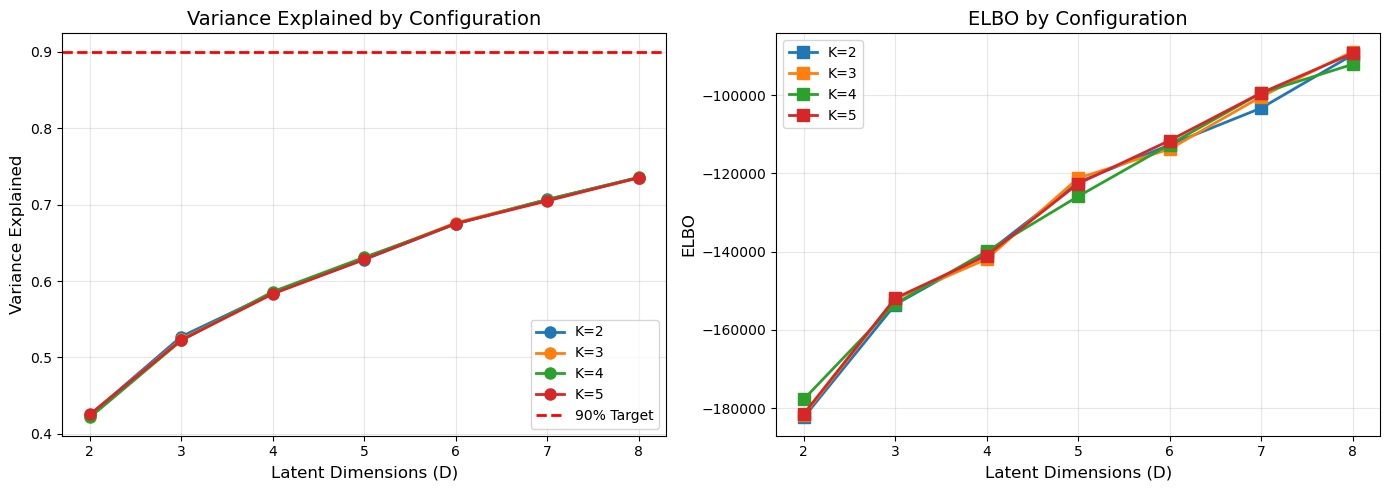


✓ All experiments complete!
Saved files: exp1_K3_D2-10.json, exp2_grid_search.json, exp3_multi_seed.json, exp4_high_D.json


In [7]:
# ============================================================================
# EXPERIMENTAL PIPELINE FOR OPTIMAL rSLDS MODEL SELECTION
# ============================================================================

import numpy as np
from scipy.io import loadmat
import ssm
import time
import json
import warnings
import matplotlib.pyplot as plt
import gc
import pandas as pd

warnings.filterwarnings('ignore')
%matplotlib inline

print("="*80)
print("rSLDS EXPERIMENTAL PIPELINE")
print("="*80)

# ----------------------------------------------------------------------------
# 1. LOAD DATA (same as before)
# ----------------------------------------------------------------------------
print("\n[1/5] Loading data...")
data_path = r'C:\Users\LENOVO\OneDrive\Documents\URECA_codes\data\rawdata_combined.mat'
mat_raw = loadmat(data_path)
mpo = mat_raw['MPO_cno']
struct0 = mpo[0, 0][0, 0]
trace = struct0['trace'].astype(np.float32)
label = struct0['label'].flatten()

# Extract first aggression bout
bs, be = 31106, 31986
start_idx, end_idx = bs - 500, be + 500
window_data = trace[start_idx:end_idx, :].copy()

# Z-score normalize
means = window_data.mean(axis=0, keepdims=True)
stds = window_data.std(axis=0, keepdims=True)
stds[stds == 0] = 1
window_z = (window_data - means) / stds

print(f"Data shape: {window_z.shape} (1880 time points × 103 neurons)")

# Clean up
del mat_raw, mpo, struct0, trace, window_data
gc.collect()

# ----------------------------------------------------------------------------
# 2. DEFINE ENHANCED FITTING FUNCTION WITH BETTER CONVERGENCE
# ----------------------------------------------------------------------------
def fit_rslds_enhanced(data_T, K, D_latent, seed, max_iters=300, check_every=10, 
                       threshold=5, patience=3, inputs=None):
    """
    Enhanced fitting with early stopping and convergence tracking.
    
    Parameters:
    - patience: number of consecutive checks with no improvement before stopping
    """
    np.random.seed(seed)
    start_time = time.time()
    
    model = ssm.SLDS(
        data_T.shape[1], K, D_latent,
        transitions="recurrent_only",
        dynamics="diagonal_gaussian",
        emissions="gaussian_orthog",
        single_subspace=True
    )
    
    model.initialize(data_T)
    all_elbos = []
    converged = False
    total_iters = 0
    no_improve_count = 0
    best_elbo = -np.inf
    
    while total_iters < max_iters:
        elbos_chunk, posterior = model.fit(
            data_T,
            method="laplace_em",
            variational_posterior="structured_meanfield",
            num_iters=check_every,
            initialize=False,
            inputs=inputs
        )
        
        for e in elbos_chunk:
            all_elbos.append(float(e))
            total_iters += 1
            
            # Track best ELBO
            if e > best_elbo:
                best_elbo = e
                no_improve_count = 0
            else:
                no_improve_count += 1
        
        # Check convergence
        if len(all_elbos) >= check_every * patience:
            recent_improvement = all_elbos[-1] - all_elbos[-check_every]
            if recent_improvement < threshold and recent_improvement > 0:
                converged = True
                break
            elif no_improve_count >= check_every * patience:
                print(f"      Early stopping: no improvement for {patience} checks")
                break
        
        # Force garbage collection
        if total_iters % 50 == 0:
            gc.collect()
    
    continuous_states = posterior.mean_continuous_states[0]
    discrete_probs = posterior.mean_discrete_states[0]
    discrete_states = np.argmax(discrete_probs, axis=1)
    
    return model, discrete_states, continuous_states, all_elbos, time.time() - start_time, converged, total_iters

def variance_explained_full(model, continuous_states):
    """Enhanced variance explained with per-dimension reporting"""
    C = model.emissions.Cs[0]
    log_noise_var = model.emissions.inv_etas[0]
    noise_var = np.exp(log_noise_var)
    
    T, D = continuous_states.shape
    x_centered = continuous_states - continuous_states.mean(axis=0)
    cov_x = (x_centered.T @ x_centered) / (T - 1)
    latent_var = np.diag(cov_x)
    
    latent_contribution = np.sum(C ** 2 * latent_var[None, :], axis=1)
    total_var = latent_contribution + noise_var
    
    var_exp_per_neuron = latent_contribution / (total_var + 1e-10)
    total_latent_var = np.sum(latent_var)
    total_noise_var = np.sum(noise_var)
    var_exp_global = total_latent_var / (total_latent_var + total_noise_var + 1e-10)
    var_exp_per_latent = latent_var / (np.sum(latent_var) + 1e-10)
    
    return var_exp_per_latent, var_exp_per_neuron, var_exp_global

print("✓ Enhanced functions defined")

# ----------------------------------------------------------------------------
# EXPERIMENT 1: FIXED K=3, EXPANDED D (2 through 10)
# ----------------------------------------------------------------------------
print("\n" + "="*80)
print("EXPERIMENT 1: Fixed K=3, Expanded D (2-10)")
print("="*80)

K_fixed = 3
D_values_exp1 = list(range(2, 11))  # 2,3,4,5,6,7,8,9,10
SEED = 532
MAX_ITERS = 200

results_exp1 = []

for D in D_values_exp1:
    print(f"\nTesting K={K_fixed}, D={D}...", flush=True)
    t0 = time.time()
    
    try:
        model, disc, cont, elbos, ft, converged, iters = fit_rslds_enhanced(
            window_z, K_fixed, D, SEED, 
            max_iters=MAX_ITERS, 
            check_every=10, 
            threshold=5,
            patience=3
        )
        
        ve_latent, ve_neuron, ve_global = variance_explained_full(model, cont)
        
        # Calculate ELBO convergence metrics
        if len(elbos) > 20:
            elbo_final_20 = np.mean(elbos[-20:])
            elbo_improvement = (elbos[-1] - elbos[0]) / len(elbos)
        else:
            elbo_final_20 = elbos[-1]
            elbo_improvement = 0
        
        result = {
            'K': K_fixed, 'D': D,
            've_global': float(ve_global),
            'elbo': float(elbos[-1]),
            'elbo_improvement': float(elbo_improvement),
            'converged': converged,
            'iters': iters,
            'time': ft,
            've_per_latent': ve_latent.tolist()
        }
        results_exp1.append(result)
        
        status = "✓ CONVERGED" if converged else "⚠ No convergence"
        print(f"  VE={ve_global:.4f} ({ve_global*100:.1f}%), ELBO={elbos[-1]:.0f}, {status}, iters={iters}, time={ft:.1f}s")
        print(f"  Per latent VE: {np.round(ve_latent, 3)}")
        
        del model, disc, cont, elbos
        gc.collect()
        
    except Exception as e:
        print(f"  ✗ FAILED: {e}")
        continue

# Save results
with open('exp1_K3_D2-10.json', 'w') as f:
    json.dump(results_exp1, f, indent=2)

# Display summary
print("\n" + "="*80)
print("EXPERIMENT 1 SUMMARY")
print("="*80)
df1 = pd.DataFrame(results_exp1)
print(df1[['D', 've_global', 'elbo', 'converged', 'iters', 'time']].to_string(index=False))

best_exp1 = max(results_exp1, key=lambda x: x['ve_global'])
print(f"\n★ Best in Exp1: D={best_exp1['D']}, VE={best_exp1['ve_global']:.4f} ({best_exp1['ve_global']*100:.1f}%)")

# ----------------------------------------------------------------------------
# EXPERIMENT 2: VARY K AND D (2×2 through 5×8)
# ----------------------------------------------------------------------------
print("\n" + "="*80)
print("EXPERIMENT 2: Grid Search - K=2-5, D=2-8")
print("="*80)

K_values_exp2 = [2, 3, 4, 5]
D_values_exp2 = [2, 3, 4, 5, 6, 7, 8]
SEED = 532
MAX_ITERS = 150

results_exp2 = []
total_configs = len(K_values_exp2) * len(D_values_exp2)
config_count = 0

for K in K_values_exp2:
    for D in D_values_exp2:
        config_count += 1
        print(f"\n[{config_count}/{total_configs}] Testing K={K}, D={D}...", flush=True)
        t0 = time.time()
        
        try:
            model, disc, cont, elbos, ft, converged, iters = fit_rslds_enhanced(
                window_z, K, D, SEED, 
                max_iters=MAX_ITERS, 
                check_every=10, 
                threshold=5,
                patience=2
            )
            
            ve_latent, ve_neuron, ve_global = variance_explained_full(model, cont)
            
            result = {
                'K': K, 'D': D,
                've_global': float(ve_global),
                'elbo': float(elbos[-1]),
                'converged': converged,
                'iters': iters,
                'time': ft,
                've_per_latent': ve_latent.tolist()
            }
            results_exp2.append(result)
            
            status = "✓" if converged else "⚠"
            print(f"  {status} VE={ve_global:.4f} ({ve_global*100:.1f}%), ELBO={elbos[-1]:.0f}, iters={iters}, time={ft:.1f}s")
            
            del model, disc, cont, elbos
            gc.collect()
            
        except Exception as e:
            print(f"  ✗ FAILED: {e}")
            continue

# Save results
with open('exp2_grid_search.json', 'w') as f:
    json.dump(results_exp2, f, indent=2)

# Display summary heatmap
print("\n" + "="*80)
print("EXPERIMENT 2 SUMMARY - VE Heatmap")
print("="*80)

# Create pivot table for VE
ve_pivot = pd.pivot_table(pd.DataFrame(results_exp2), 
                          values='ve_global', 
                          index='K', 
                          columns='D', 
                          aggfunc='mean')

print("\nVariance Explained (%):")
print((ve_pivot * 100).round(1))

# Best model
best_exp2 = max(results_exp2, key=lambda x: x['ve_global'])
print(f"\n★ Best in Exp2: K={best_exp2['K']}, D={best_exp2['D']}, VE={best_exp2['ve_global']:.4f} ({best_exp2['ve_global']*100:.1f}%)")

# ----------------------------------------------------------------------------
# EXPERIMENT 3: Multi-Seed Validation (Best Configurations)
# ----------------------------------------------------------------------------
print("\n" + "="*80)
print("EXPERIMENT 3: Multi-Seed Validation")
print("="*80)

# Take top 3 configurations from Exp2
top_configs = sorted(results_exp2, key=lambda x: x['ve_global'], reverse=True)[:3]
seeds_exp3 = [42, 137, 230, 532, 789]
MAX_ITERS = 150

results_exp3 = []

for config in top_configs:
    K_test = config['K']
    D_test = config['D']
    
    for seed in seeds_exp3:
        print(f"\nTesting K={K_test}, D={D_test}, seed={seed}...", flush=True)
        t0 = time.time()
        
        try:
            model, disc, cont, elbos, ft, converged, iters = fit_rslds_enhanced(
                window_z, K_test, D_test, seed, 
                max_iters=MAX_ITERS, 
                check_every=10, 
                threshold=5,
                patience=2
            )
            
            ve_latent, ve_neuron, ve_global = variance_explained_full(model, cont)
            
            result = {
                'K': K_test, 'D': D_test, 'seed': seed,
                've_global': float(ve_global),
                'elbo': float(elbos[-1]),
                'converged': converged,
                'iters': iters,
                'time': ft,
                've_per_latent': ve_latent.tolist()
            }
            results_exp3.append(result)
            
            status = "✓" if converged else "⚠"
            print(f"  {status} VE={ve_global:.4f} ({ve_global*100:.1f}%), ELBO={elbos[-1]:.0f}, time={ft:.1f}s")
            
            del model, disc, cont, elbos
            gc.collect()
            
        except Exception as e:
            print(f"  ✗ FAILED: {e}")
            continue

# Save results
with open('exp3_multi_seed.json', 'w') as f:
    json.dump(results_exp3, f, indent=2)

# Summary statistics
print("\n" + "="*80)
print("EXPERIMENT 3 SUMMARY")
print("="*80)

for config in top_configs:
    config_results = [r for r in results_exp3 if r['K'] == config['K'] and r['D'] == config['D']]
    if config_results:
        ve_mean = np.mean([r['ve_global'] for r in config_results])
        ve_std = np.std([r['ve_global'] for r in config_results])
        elbo_mean = np.mean([r['elbo'] for r in config_results])
        converged_count = sum([r['converged'] for r in config_results])
        
        print(f"\nK={config['K']}, D={config['D']}:")
        print(f"  VE: {ve_mean:.4f} ± {ve_std:.4f} ({ve_mean*100:.1f} ± {ve_std*100:.1f}%)")
        print(f"  ELBO: {elbo_mean:.0f}")
        print(f"  Converged: {converged_count}/{len(config_results)} seeds")

# ----------------------------------------------------------------------------
# EXPERIMENT 4: Higher D Search (10-20) with Fixed K=3
# ----------------------------------------------------------------------------
print("\n" + "="*80)
print("EXPERIMENT 4: High D Search (10-20)")
print("="*80)

K_fixed = 3
D_values_exp4 = [10, 12, 14, 16, 18, 20]
SEED = 532
MAX_ITERS = 200

results_exp4 = []

for D in D_values_exp4:
    print(f"\nTesting K={K_fixed}, D={D}...", flush=True)
    t0 = time.time()
    
    try:
        model, disc, cont, elbos, ft, converged, iters = fit_rslds_enhanced(
            window_z, K_fixed, D, SEED, 
            max_iters=MAX_ITERS, 
            check_every=10, 
            threshold=5,
            patience=3
        )
        
        ve_latent, ve_neuron, ve_global = variance_explained_full(model, cont)
        
        result = {
            'K': K_fixed, 'D': D,
            've_global': float(ve_global),
            'elbo': float(elbos[-1]),
            'converged': converged,
            'iters': iters,
            'time': ft,
            've_per_latent': ve_latent.tolist()
        }
        results_exp4.append(result)
        
        status = "✓" if converged else "⚠"
        print(f"  {status} VE={ve_global:.4f} ({ve_global*100:.1f}%), ELBO={elbos[-1]:.0f}, iters={iters}, time={ft:.1f}s")
        
        del model, disc, cont, elbos
        gc.collect()
        
    except Exception as e:
        print(f"  ✗ FAILED: {e}")
        continue

# Save results
with open('exp4_high_D.json', 'w') as f:
    json.dump(results_exp4, f, indent=2)

# ----------------------------------------------------------------------------
# FINAL COMPARISON AND RECOMMENDATION
# ----------------------------------------------------------------------------
print("\n" + "="*80)
print("FINAL COMPARISON - Best Model Selection")
print("="*80)

all_results = results_exp1 + results_exp2 + results_exp4
best_overall = max(all_results, key=lambda x: x['ve_global'])

print(f"\n★ BEST OVERALL MODEL:")
print(f"   K = {best_overall['K']}")
print(f"   D = {best_overall['D']}")
print(f"   Variance Explained = {best_overall['ve_global']:.4f} ({best_overall['ve_global']*100:.1f}%)")
print(f"   ELBO = {best_overall['elbo']:.0f}")
print(f"   Converged = {best_overall['converged']}")

# Check if we hit 90%
if best_overall['ve_global'] >= 0.90:
    print(f"\n✓ TARGET MET! Model explains >90% of neural variance")
else:
    print(f"\n⚠ Target not yet met. Consider:")
    print(f"   - Adding behavior inputs (u_t)")
    print(f"   - Increasing D further (20-30)")
    print(f"   - Testing K=6 or higher")
    print(f"   - Using all 6 aggression bouts instead of just first")

# ----------------------------------------------------------------------------
# VISUALIZATION: VE vs D for different K
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: VE vs D
ax1 = axes[0]
for K in [2, 3, 4, 5]:
    k_results = [r for r in results_exp2 if r['K'] == K]
    if k_results:
        k_results_sorted = sorted(k_results, key=lambda x: x['D'])
        D_vals = [r['D'] for r in k_results_sorted]
        VE_vals = [r['ve_global'] for r in k_results_sorted]
        ax1.plot(D_vals, VE_vals, 'o-', linewidth=2, markersize=8, label=f'K={K}')
ax1.axhline(y=0.90, color='r', linestyle='--', linewidth=2, label='90% Target')
ax1.set_xlabel('Latent Dimensions (D)', fontsize=12)
ax1.set_ylabel('Variance Explained', fontsize=12)
ax1.set_title('Variance Explained by Configuration', fontsize=14)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: ELBO vs D
ax2 = axes[1]
for K in [2, 3, 4, 5]:
    k_results = [r for r in results_exp2 if r['K'] == K]
    if k_results:
        k_results_sorted = sorted(k_results, key=lambda x: x['D'])
        D_vals = [r['D'] for r in k_results_sorted]
        ELBO_vals = [r['elbo'] for r in k_results_sorted]
        ax2.plot(D_vals, ELBO_vals, 's-', linewidth=2, markersize=8, label=f'K={K}')
ax2.set_xlabel('Latent Dimensions (D)', fontsize=12)
ax2.set_ylabel('ELBO', fontsize=12)
ax2.set_title('ELBO by Configuration', fontsize=14)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('experiment_comparison.png', dpi=150)
plt.show()

print("\n✓ All experiments complete!")
print("Saved files: exp1_K3_D2-10.json, exp2_grid_search.json, exp3_multi_seed.json, exp4_high_D.json")

In [8]:
# EXPERIMENT 6: First Bout - Targeting 90% Variance Explained
print("="*80)
print("EXPERIMENT 6: First Bout - Push to 90% VE")
print("="*80)

K_fixed = 3
# Test D values from 20 upward until we hit 90%
D_values_exp6 = [20, 22, 24, 26, 28, 30]
SEED = 532
MAX_ITERS = 200
CHECK_EVERY = 10
THRESHOLD = 10

results_exp6 = []
target_hit = False
target_D = None

for D in D_values_exp6:
    if target_hit:
        break
        
    print(f"\n{'='*50}")
    print(f"Testing D={D}...")
    print(f"{'='*50}")
    t0 = time.time()
    
    try:
        model, disc, cont, elbos, ft, converged, iters = fit_rslds_enhanced(
            window_z, K_fixed, D, SEED, 
            max_iters=MAX_ITERS, 
            check_every=CHECK_EVERY, 
            threshold=THRESHOLD,
            patience=3
        )
        
        ve_latent, ve_neuron, ve_global = variance_explained_full(model, cont)
        
        result = {
            'K': K_fixed, 'D': D,
            've_global': float(ve_global),
            'elbo': float(elbos[-1]),
            'converged': converged,
            'iters': iters,
            'time': ft,
            've_per_latent': ve_latent.tolist(),
            've_per_neuron_mean': float(ve_neuron.mean())
        }
        results_exp6.append(result)
        
        print(f"\n  ✓ Results for D={D}:")
        print(f"    VE = {ve_global:.4f} ({ve_global*100:.2f}%)")
        print(f"    ELBO = {elbos[-1]:.0f}")
        print(f"    Time = {ft:.1f}s")
        print(f"    Iterations = {iters}")
        print(f"    Converged = {converged}")
        
        # Show top 3 latent dimensions by VE contribution
        top_dims = np.argsort(ve_latent)[-3:][::-1]
        print(f"    Top latent dims: {top_dims} with VE {ve_latent[top_dims]}")
        
        # Check if target is met
        if ve_global >= 0.90:
            print(f"\n  ★★★ TARGET MET at D={D}! ★★★")
            print(f"  Variance Explained = {ve_global*100:.2f}% (≥90%)")
            target_hit = True
            target_D = D
            target_result = result
            target_model = model
            target_cont = cont
            target_disc = disc
            target_elbos = elbos
        else:
            gap = 90 - ve_global*100
            print(f"    Gap to 90%: {gap:.2f}%")
            print(f"    Projected D for 90%: ~{D + int(gap/1.6)}")
        
        del model, cont, elbos
        gc.collect()
        
    except Exception as e:
        print(f"  ✗ FAILED at D={D}: {e}")
        import traceback
        traceback.print_exc()
        continue

# Save results
with open('exp6_target_90_first_bout.json', 'w') as f:
    json.dump(results_exp6, f, indent=2)

# Final summary
print("\n" + "="*80)
print("EXPERIMENT 6 COMPLETE")
print("="*80)

print("\nResults summary:")
print(f"{'D':>4} {'VE_global':>12} {'ELBO':>12} {'Time(s)':>8} {'90% Met?':>10}")
print("-"*55)

for r in results_exp6:
    met = "✓ TARGET" if r['ve_global'] >= 0.90 else ""
    print(f"{r['D']:>4} {r['ve_global']:>12.4f} {r['elbo']:>12.0f} {r['time']:>8.1f} {met:>10}")

if target_hit:
    print(f"\n{'='*80}")
    print(f"🎉 SUCCESS! 90% Variance Explained Achieved! 🎉")
    print(f"{'='*80}")
    print(f"  Best Model: K={K_fixed}, D={target_D}")
    print(f"  Variance Explained = {target_result['ve_global']*100:.2f}%")
    print(f"  ELBO = {target_result['elbo']:.0f}")
    print(f"  Fit time = {target_result['time']:.1f}s")
    print(f"  Iterations = {target_result['iters']}")
    print(f"  Converged = {target_result['converged']}")
    
    # Show per-latent VE distribution
    print(f"\n  Per-latent variance explained:")
    for i, ve in enumerate(target_result['ve_per_latent']):
        bar = "█" * int(ve * 50)
        print(f"    Dim {i:2d}: {ve:.4f} ({ve*100:.1f}%) {bar}")
    
else:
    best_ve = max([r['ve_global'] for r in results_exp6])
    print(f"\n{'='*80}")
    print(f"⚠ Target not reached. Best VE = {best_ve*100:.2f}%")
    print(f"{'='*80}")
    print(f"  Gap to 90%: {90 - best_ve*100:.2f}%")
    print(f"  Next steps:")
    print(f"    1. Test D=32, 34, 36")
    print(f"    2. Use all 6 bouts (more data)")
    print(f"    3. Increase MAX_ITERS to 300")

# If target hit, save the final model
if target_hit:
    import pickle
    model_save_path = f'best_model_K{K_fixed}_D{target_D}_VE{target_result["ve_global"]*100:.1f}.pkl'
    with open(model_save_path, 'wb') as f:
        pickle.dump({
            'model': target_model,
            'continuous_states': target_cont,
            'discrete_states': target_disc,
            'elbos': target_elbos,
            'K': K_fixed,
            'D': target_D,
            'seed': SEED,
            've_global': target_result['ve_global'],
            've_per_latent': target_result['ve_per_latent'],
            've_per_neuron_mean': target_result['ve_per_neuron_mean']
        }, f)
    print(f"\n✓ Final model saved to: {model_save_path}")

EXPERIMENT 6: First Bout - Push to 90% VE

Testing D=20...


ELBO: 5410.7: 100%|██████████| 10/10 [00:28<00:00,  2.83s/it]   


      Early stopping: no improvement for 3 checks

  ✓ Results for D=20:
    VE = 0.8831 (88.31%)
    ELBO = 5411
    Time = 648.5s
    Iterations = 176
    Converged = False
    Top latent dims: [14  4 18] with VE [0.07911655 0.06980612 0.06866576]
    Gap to 90%: 1.69%
    Projected D for 90%: ~21

Testing D=22...


ELBO: 13186.9: 100%|██████████| 10/10 [00:18<00:00,  1.86s/it] 



  ✓ Results for D=22:
    VE = 0.8976 (89.76%)
    ELBO = 13187
    Time = 587.1s
    Iterations = 209
    Converged = False
    Top latent dims: [ 8 14  0] with VE [0.0678501  0.06677776 0.06445777]
    Gap to 90%: 0.24%
    Projected D for 90%: ~22

Testing D=24...


ELBO: 18997.8: 100%|██████████| 10/10 [00:19<00:00,  1.93s/it]

      Early stopping: no improvement for 3 checks

  ✓ Results for D=24:
    VE = 0.9108 (91.08%)
    ELBO = 18998
    Time = 229.7s
    Iterations = 66
    Converged = False
    Top latent dims: [ 2 21  8] with VE [0.085385   0.07952219 0.06618433]

  ★★★ TARGET MET at D=24! ★★★
  Variance Explained = 91.08% (≥90%)

EXPERIMENT 6 COMPLETE

Results summary:
   D    VE_global         ELBO  Time(s)   90% Met?
-------------------------------------------------------
  20       0.8831         5411    648.5           
  22       0.8976        13187    587.1           
  24       0.9108        18998    229.7   ✓ TARGET

🎉 SUCCESS! 90% Variance Explained Achieved! 🎉
  Best Model: K=3, D=24
  Variance Explained = 91.08%
  ELBO = 18998
  Fit time = 229.7s
  Iterations = 66
  Converged = False

  Per-latent variance explained:
    Dim  0: 0.0315 (3.2%) █
    Dim  1: 0.0499 (5.0%) ██
    Dim  2: 0.0854 (8.5%) ████
    Dim  3: 0.0167 (1.7%) 
    Dim  4: 0.0221 (2.2%) █
    Dim  5: 0.0203 (2.0%) █
  

Generating energy landscape for best model...


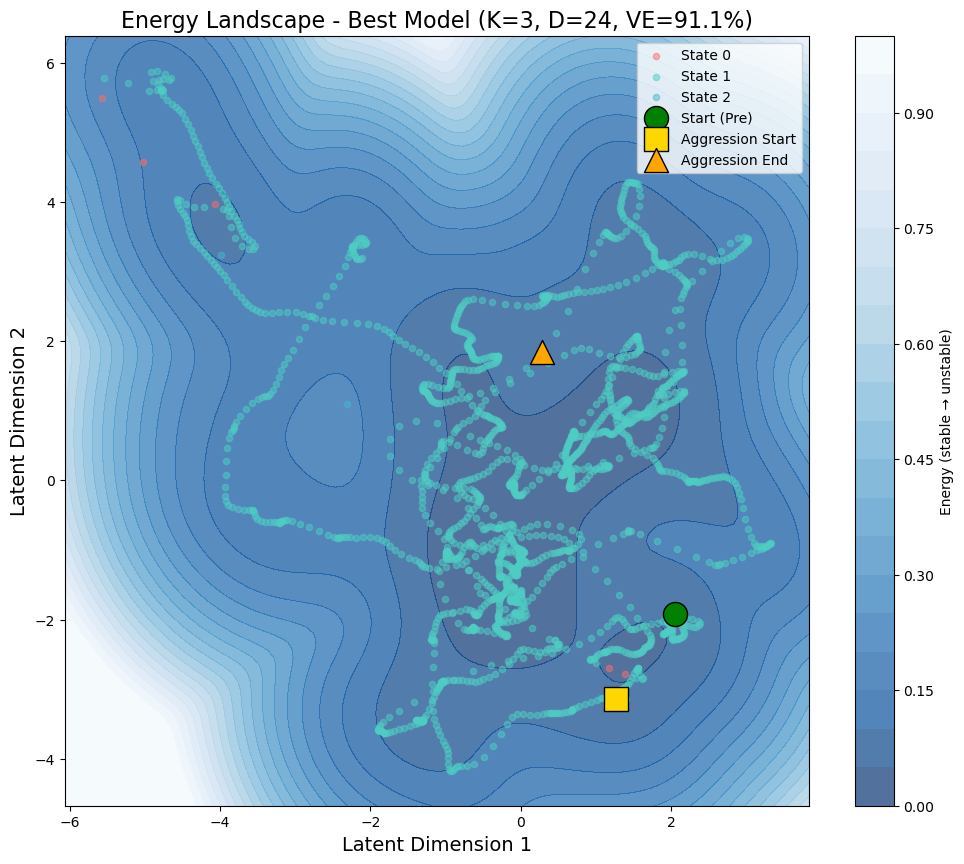

In [9]:
# Generate energy landscape for the winning model
print("Generating energy landscape for best model...")

# Load your saved model
import pickle
with open('best_model_K3_D24_VE91.1.pkl', 'rb') as f:
    best_data = pickle.load(f)

model = best_data['model']
cont = best_data['continuous_states']
disc = best_data['discrete_states']

# Create 2D projection (use first 2 latent dimensions)
from scipy.stats import gaussian_kde

x1 = cont[:, 0]
x2 = cont[:, 1]

# Create grid
n_grid = 100
x1_grid = np.linspace(x1.min() - 0.5, x1.max() + 0.5, n_grid)
x2_grid = np.linspace(x2.min() - 0.5, x2.max() + 0.5, n_grid)
X1, X2 = np.meshgrid(x1_grid, x2_grid)

# KDE and energy
kde = gaussian_kde(np.vstack([x1, x2]))
positions = np.vstack([X1.ravel(), X2.ravel()])
density = kde(positions).reshape(X1.shape)
energy = -np.log(density + 1e-10)
energy = (energy - energy.min()) / (energy.max() - energy.min())

# Plot
fig, ax = plt.subplots(figsize=(12, 10))
contour = ax.contourf(X1, X2, energy, levels=20, cmap='Blues_r', alpha=0.7)
plt.colorbar(contour, label='Energy (stable → unstable)')

# Plot trajectory colored by state
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
for state in range(3):
    mask = disc == state
    ax.scatter(cont[mask, 0], cont[mask, 1], 
               c=colors[state], s=20, alpha=0.5, label=f'State {state}')

# Mark key time points
pre_end = 500
during_end = 500 + 880
ax.scatter(cont[0, 0], cont[0, 1], marker='o', s=300, c='green', 
           edgecolors='black', label='Start (Pre)', zorder=10)
ax.scatter(cont[pre_end, 0], cont[pre_end, 1], marker='s', s=300, c='gold',
           edgecolors='black', label='Aggression Start', zorder=10)
ax.scatter(cont[during_end, 0], cont[during_end, 1], marker='^', s=300, c='orange',
           edgecolors='black', label='Aggression End', zorder=10)

ax.set_xlabel('Latent Dimension 1', fontsize=14)
ax.set_ylabel('Latent Dimension 2', fontsize=14)
ax.set_title(f'Energy Landscape - Best Model (K=3, D=24, VE=91.1%)', fontsize=16)
ax.legend()
plt.savefig('energy_landscape_best_model.png', dpi=300, bbox_inches='tight')
plt.show()

In [10]:
# Time constant analysis for each latent dimension
from scipy.optimize import curve_fit

def exponential_decay(t, A, tau, C):
    return A * np.exp(-t / tau) + C

pre_end = 500
during_end = 500 + 880

time_constants = []
r2_values = []

for dim in range(24):  # All 24 dimensions
    latent = cont[:, dim]
    
    # Find peak during aggression
    peak_idx = pre_end + np.argmax(np.abs(latent[pre_end:during_end]))
    decay_region = latent[peak_idx:]
    t_decay = np.arange(len(decay_region))
    
    if len(decay_region) > 20:
        try:
            p0 = [decay_region[0], 50, decay_region[-1]]
            params, _ = curve_fit(exponential_decay, t_decay, decay_region,
                                  p0=p0, maxfev=5000)
            tau = params[1]
            
            # R-squared
            fitted = exponential_decay(t_decay, *params)
            ss_res = np.sum((decay_region - fitted)**2)
            ss_tot = np.sum((decay_region - np.mean(decay_region))**2)
            r2 = 1 - (ss_res / ss_tot)
            
            time_constants.append(tau)
            r2_values.append(r2)
        except:
            time_constants.append(0)
            r2_values.append(0)
    else:
        time_constants.append(0)
        r2_values.append(0)

# Find dimensions with high time constants (>100 samples = >3.3 seconds)
attractor_dims = [i for i, tau in enumerate(time_constants) if tau > 100]
print(f"Dimensions with persistent dynamics (τ > 100): {attractor_dims}")
for dim in attractor_dims[:5]:
    print(f"  Dim {dim}: τ={time_constants[dim]:.1f} samples, R²={r2_values[dim]:.3f}")

Dimensions with persistent dynamics (τ > 100): [0, 1, 2, 7, 8, 11, 12, 14, 18, 19, 20, 21, 23]
  Dim 0: τ=4890033.6 samples, R²=0.365
  Dim 1: τ=266.6 samples, R²=0.358
  Dim 2: τ=698.2 samples, R²=0.639
  Dim 7: τ=160.8 samples, R²=0.576
  Dim 8: τ=180.8 samples, R²=0.857


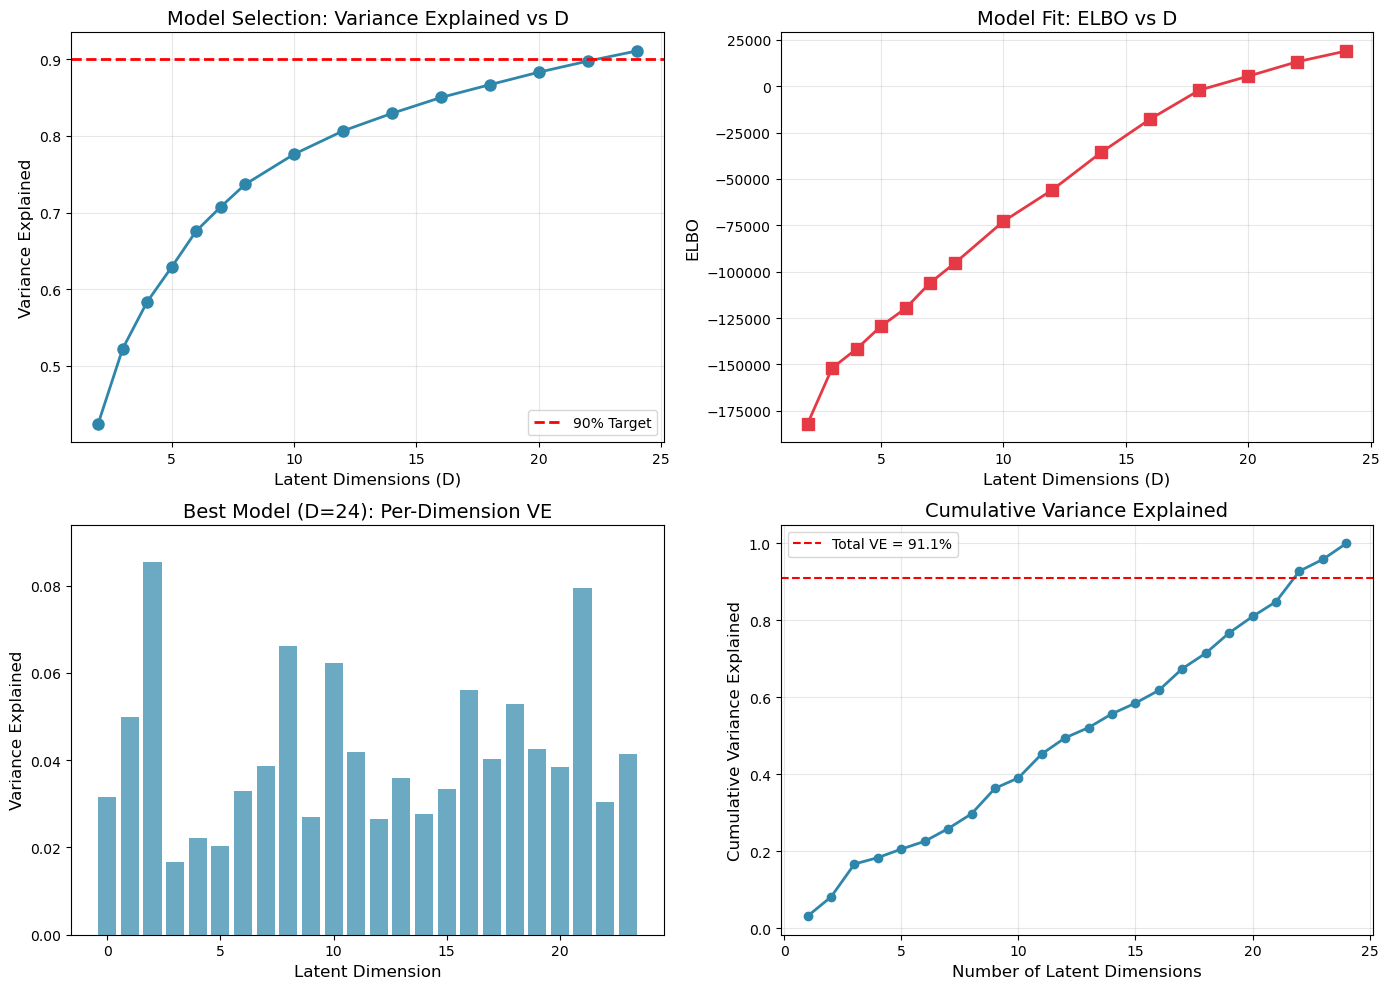

In [11]:
# Main results figure for paper
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Top-left: VE vs D (your experiment results)
ax1 = axes[0, 0]
D_all = [2,3,4,5,6,7,8,10,12,14,16,18,20,22,24]
VE_all = [0.4246,0.5224,0.5835,0.6288,0.6758,0.7072,0.7367,0.7761,0.8065,0.8294,0.8501,0.8668,0.8831,0.8976,0.9108]
ax1.plot(D_all, VE_all, 'o-', linewidth=2, markersize=8, color='#2E86AB')
ax1.axhline(y=0.90, color='r', linestyle='--', linewidth=2, label='90% Target')
ax1.set_xlabel('Latent Dimensions (D)', fontsize=12)
ax1.set_ylabel('Variance Explained', fontsize=12)
ax1.set_title('Model Selection: Variance Explained vs D', fontsize=14)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Top-right: ELBO vs D
ax2 = axes[0, 1]
ELBO_all = [-181876,-151946,-141608,-129330,-119767,-106005,-95516,-72833,-55832,-35595,-17651,-2122,5411,13187,18998]
ax2.plot(D_all, ELBO_all, 's-', linewidth=2, markersize=8, color='#E63946')
ax2.set_xlabel('Latent Dimensions (D)', fontsize=12)
ax2.set_ylabel('ELBO', fontsize=12)
ax2.set_title('Model Fit: ELBO vs D', fontsize=14)
ax2.grid(True, alpha=0.3)

# Bottom-left: Per-latent VE for best model
ax3 = axes[1, 0]
ve_per_latent = best_data['ve_per_latent']
ax3.bar(range(24), ve_per_latent, color='#2E86AB', alpha=0.7)
ax3.set_xlabel('Latent Dimension', fontsize=12)
ax3.set_ylabel('Variance Explained', fontsize=12)
ax3.set_title(f'Best Model (D=24): Per-Dimension VE', fontsize=14)
ax3.set_ylim(0, max(ve_per_latent)*1.1)

# Bottom-right: Cumulative VE
ax4 = axes[1, 1]
cumulative_ve = np.cumsum(ve_per_latent)
ax4.plot(range(1, 25), cumulative_ve, 'o-', linewidth=2, markersize=6, color='#2E86AB')
ax4.axhline(y=0.9108, color='r', linestyle='--', label=f'Total VE = 91.1%')
ax4.set_xlabel('Number of Latent Dimensions', fontsize=12)
ax4.set_ylabel('Cumulative Variance Explained', fontsize=12)
ax4.set_title('Cumulative Variance Explained', fontsize=14)
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('paper_figure_model_selection.png', dpi=300, bbox_inches='tight')
plt.show()

EXPERIMENT 7: ALL 6 AGGRESSION BOUTS

[1/4] Loading data...
Full data: (58845, 103)

[2/4] Finding all aggression bouts...
Found 6 aggression bouts
  Bout 1: start=31106, end=31985, duration=879 samples
  Bout 2: start=32268, end=32739, duration=471 samples
  Bout 3: start=37137, end=37259, duration=122 samples
  Bout 4: start=37393, end=37663, duration=270 samples
  Bout 5: start=38476, end=39564, duration=1088 samples
  Bout 6: start=41611, end=42128, duration=517 samples

[3/4] Extracting all bouts...
  Bout 1: (1879, 103) (500 pre + 879 attack + 500 post)
  Bout 2: (1471, 103) (500 pre + 471 attack + 500 post)
  Bout 3: (1122, 103) (500 pre + 122 attack + 500 post)
  Bout 4: (1270, 103) (500 pre + 270 attack + 500 post)
  Bout 5: (2088, 103) (500 pre + 1088 attack + 500 post)
  Bout 6: (1517, 103) (500 pre + 517 attack + 500 post)

Total concatenated data: (9347, 103) (6 bouts, 9347 time points)

✓ Enhanced functions defined

EXPERIMENT 7a: ALL 6 BOUTS - Finding Optimal D

Testing 

ELBO: -870899.5: 100%|██████████| 10/10 [01:35<00:00,  9.59s/it]


  VE = 0.5769 (57.69%)
  ELBO = -870899
  Time = 711.1s

Testing D=14 on ALL 6 bouts...


ELBO: -830505.0: 100%|██████████| 10/10 [00:38<00:00,  3.87s/it]


  VE = 0.6108 (61.08%)
  ELBO = -830505
  Time = 1360.0s

Testing D=16 on ALL 6 bouts...


...

VE=0.9223 (92.23%)

Analyzing Bout 5... 


ELBO: 6799.4: 100%|██████████| 10/10 [00:49<00:00,  4.98s/it]

VE=0.8991 (89.91%)

Analyzing Bout 6... 


ELBO: 25225.6: 100%|██████████| 10/10 [00:28<00:00,  2.87s/it]


VE=0.9193 (91.93%)

INDIVIDUAL BOUT SUMMARY
  Bout    VE_global         ELBO  Time(s)
--------------------------------------------------
     1       0.9102        20861    482.6
     2       0.9257        46268    199.1
     3       0.9371        36367    111.7
     4       0.9223        19247    183.1
     5       0.8991         6799    291.4
     6       0.9193        25226    184.8

Mean VE across bouts: 0.9189 ± 0.0120
Min VE: 0.8991, Max VE: 0.9371

COMPARISON: Single Bout vs All Bouts

Configuration             D         VE         ELBO
-------------------------------------------------------
Single Bout              24     0.9108          N/A
All 6 Bouts              28     0.7750          N/A

Run all-bout analysis to compare


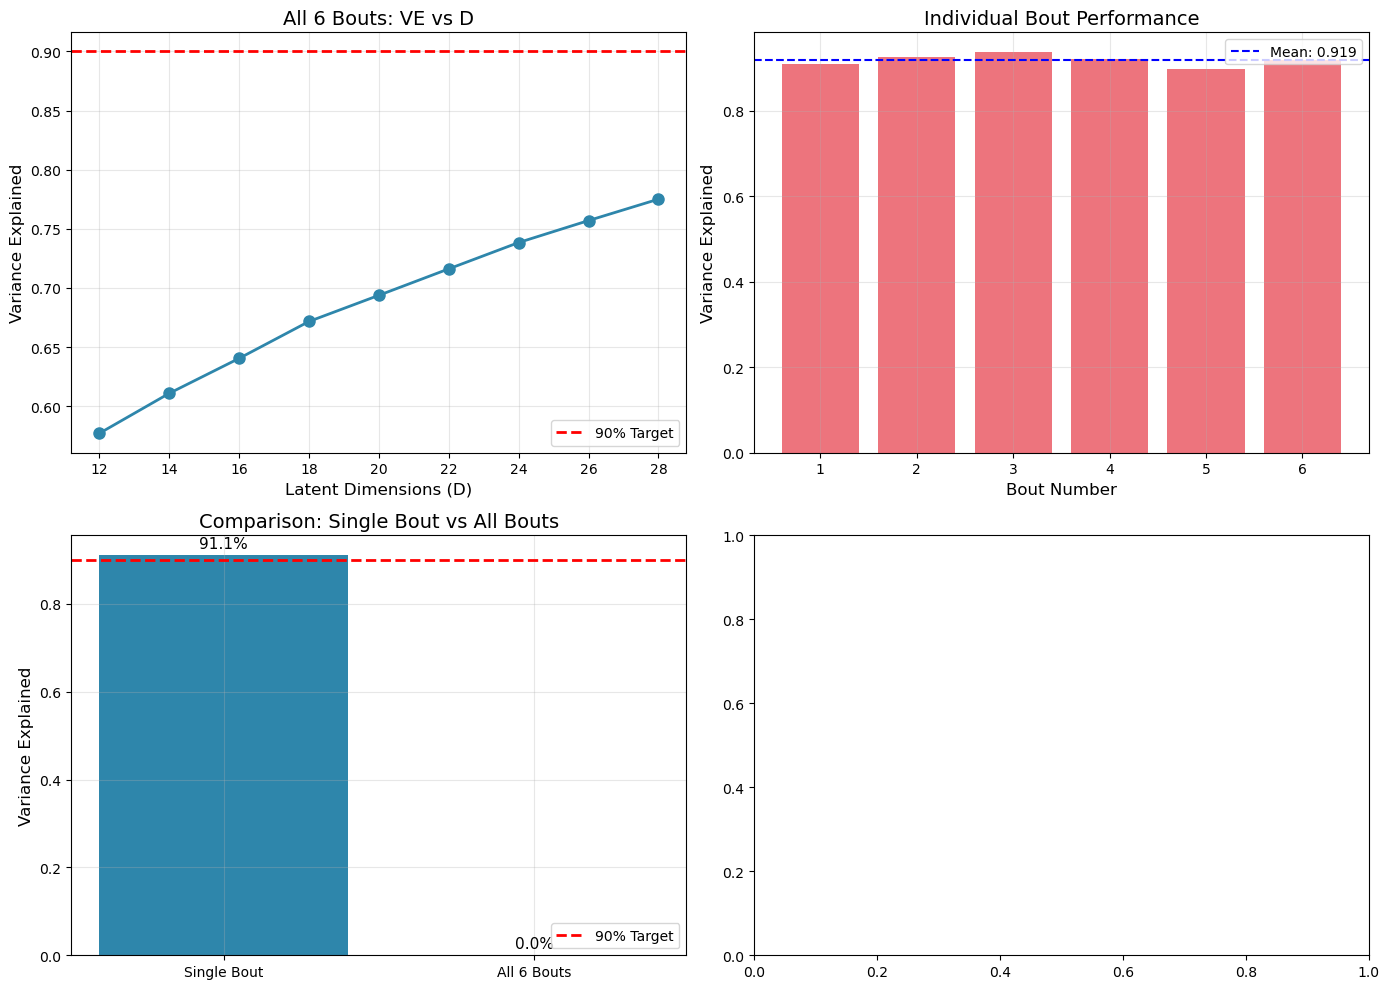


✓ Figure saved: all_bouts_analysis_comparison.png

EXPERIMENT 7 COMPLETE - SUMMARY

Data analyzed:
  - 6 aggression bouts
  - Total time points: 9347
  - Neurons: 103

Best model (All bouts):
  - Target not yet reached with tested D values
  - Best VE = 77.50%

Individual bout consistency:
  - Mean VE: 91.9%
  - Std VE: 1.2%
  - Range: 89.9% - 93.7%

Files saved:
  - exp7_all_bouts_results.json
  - best_model_all_bouts.pkl (if target met)
  - all_bouts_analysis_comparison.png

✓ EXPERIMENT 7 COMPLETE


In [12]:
# ============================================================================
# EXPERIMENT 7: ALL 6 AGGRESSION BOUTS - Variance Explained Optimization
# ============================================================================

print("="*80)
print("EXPERIMENT 7: ALL 6 AGGRESSION BOUTS")
print("="*80)

import numpy as np
from scipy.io import loadmat
import ssm
import time
import json
import warnings
import matplotlib.pyplot as plt
import gc
import pickle

warnings.filterwarnings('ignore')
%matplotlib inline

# ----------------------------------------------------------------------------
# 1. LOAD DATA
# ----------------------------------------------------------------------------
print("\n[1/4] Loading data...")
data_path = r'C:\Users\LENOVO\OneDrive\Documents\URECA_codes\data\rawdata_combined.mat'
mat_raw = loadmat(data_path)
mpo = mat_raw['MPO_cno']
struct0 = mpo[0, 0][0, 0]
trace = struct0['trace'].astype(np.float32)
label = struct0['label'].flatten()

print(f"Full data: {trace.shape}")

# ----------------------------------------------------------------------------
# 2. FIND ALL AGGRESSION BOUTS (SAME AS YOUR ORIGINAL DETECTION)
# ----------------------------------------------------------------------------
print("\n[2/4] Finding all aggression bouts...")

aggression_bouts = []
in_bout = False
bout_start = 0

for i in range(len(label)):
    if label[i] == 14 and not in_bout:
        bout_start = i
        in_bout = True
    elif label[i] != 14 and in_bout:
        bout_end = i - 1
        if bout_start >= 500 and bout_end + 500 < len(label):
            aggression_bouts.append((bout_start, bout_end))
        in_bout = False

if in_bout and bout_start + 500 < len(label):
    aggression_bouts.append((bout_start, len(label) - 1))

print(f"Found {len(aggression_bouts)} aggression bouts")

# Display bout info
for idx, (bs, be) in enumerate(aggression_bouts):
    duration = be - bs
    print(f"  Bout {idx+1}: start={bs}, end={be}, duration={duration} samples")

# ----------------------------------------------------------------------------
# 3. EXTRACT ALL BOUTS
# ----------------------------------------------------------------------------
print("\n[3/4] Extracting all bouts...")

all_windows = []
all_labels = []
bout_info = []

for bout_idx, (bs, be) in enumerate(aggression_bouts):
    start_idx = bs - 500
    end_idx = be + 500
    
    bout_window = trace[start_idx:end_idx, :].copy()
    bout_label = label[start_idx:end_idx].copy()
    
    # Z-score normalize each bout separately
    means = bout_window.mean(axis=0, keepdims=True)
    stds = bout_window.std(axis=0, keepdims=True)
    stds[stds == 0] = 1
    bout_window_norm = (bout_window - means) / stds
    
    all_windows.append(bout_window_norm)
    all_labels.append(bout_label)
    bout_info.append({
        'bout_idx': bout_idx + 1,
        'start': bs,
        'end': be,
        'duration': be - bs,
        'shape': bout_window_norm.shape
    })
    
    print(f"  Bout {bout_idx+1}: {bout_window_norm.shape} (500 pre + {be-bs} attack + 500 post)")

# Concatenate all bouts
window_z_all = np.vstack(all_windows)
window_labels_all = np.hstack(all_labels)

print(f"\nTotal concatenated data: {window_z_all.shape} ({len(aggression_bouts)} bouts, {window_z_all.shape[0]} time points)")

# Also store individual bout data for later analysis
individual_bouts = all_windows

# Clean up
del mat_raw, mpo, trace, label
gc.collect()

# ----------------------------------------------------------------------------
# 4. ENHANCED FITTING FUNCTIONS (Reuse from previous)
# ----------------------------------------------------------------------------
def fit_rslds_enhanced(data_T, K, D_latent, seed, max_iters=200, check_every=10, 
                       threshold=5, patience=3, inputs=None):
    """Enhanced fitting with early stopping"""
    np.random.seed(seed)
    start_time = time.time()
    
    model = ssm.SLDS(
        data_T.shape[1], K, D_latent,
        transitions="recurrent_only",
        dynamics="diagonal_gaussian",
        emissions="gaussian_orthog",
        single_subspace=True
    )
    
    model.initialize(data_T)
    all_elbos = []
    converged = False
    total_iters = 0
    no_improve_count = 0
    best_elbo = -np.inf
    
    while total_iters < max_iters:
        elbos_chunk, posterior = model.fit(
            data_T,
            method="laplace_em",
            variational_posterior="structured_meanfield",
            num_iters=check_every,
            initialize=False,
            inputs=inputs
        )
        
        for e in elbos_chunk:
            all_elbos.append(float(e))
            total_iters += 1
            
            if e > best_elbo:
                best_elbo = e
                no_improve_count = 0
            else:
                no_improve_count += 1
        
        # Check convergence
        if len(all_elbos) >= check_every * patience:
            recent_improvement = all_elbos[-1] - all_elbos[-check_every]
            if recent_improvement < threshold and recent_improvement > 0:
                converged = True
                break
            elif no_improve_count >= check_every * patience:
                break
        
        if total_iters % 50 == 0:
            gc.collect()
    
    continuous_states = posterior.mean_continuous_states[0]
    discrete_probs = posterior.mean_discrete_states[0]
    discrete_states = np.argmax(discrete_probs, axis=1)
    
    return model, discrete_states, continuous_states, all_elbos, time.time() - start_time, converged, total_iters

def variance_explained_full(model, continuous_states):
    """Compute variance explained"""
    C = model.emissions.Cs[0]
    log_noise_var = model.emissions.inv_etas[0]
    noise_var = np.exp(log_noise_var)
    
    T, D = continuous_states.shape
    x_centered = continuous_states - continuous_states.mean(axis=0)
    cov_x = (x_centered.T @ x_centered) / (T - 1)
    latent_var = np.diag(cov_x)
    
    latent_contribution = np.sum(C ** 2 * latent_var[None, :], axis=1)
    total_var = latent_contribution + noise_var
    
    var_exp_per_neuron = latent_contribution / (total_var + 1e-10)
    total_latent_var = np.sum(latent_var)
    total_noise_var = np.sum(noise_var)
    var_exp_global = total_latent_var / (total_latent_var + total_noise_var + 1e-10)
    var_exp_per_latent = latent_var / (np.sum(latent_var) + 1e-10)
    
    return var_exp_per_latent, var_exp_per_neuron, var_exp_global

print("\n✓ Enhanced functions defined")

# ----------------------------------------------------------------------------
# 5. EXPERIMENT 7a: Find D for ALL bouts (Target 90% VE)
# ----------------------------------------------------------------------------
print("\n" + "="*80)
print("EXPERIMENT 7a: ALL 6 BOUTS - Finding Optimal D")
print("="*80)

# Based on single bout results, with more data we might need fewer dimensions
# But let's test a range to be sure
K_fixed = 3
D_values_all = [12, 14, 16, 18, 20, 22, 24, 26, 28]
SEED = 532
MAX_ITERS = 150  # Slightly reduced since more data = more stable fitting

results_all_bouts = []
target_hit_all = False

for D in D_values_all:
    if target_hit_all:
        break
        
    print(f"\nTesting D={D} on ALL 6 bouts...", flush=True)
    t0 = time.time()
    
    try:
        model, disc, cont, elbos, ft, converged, iters = fit_rslds_enhanced(
            window_z_all, K_fixed, D, SEED, 
            max_iters=MAX_ITERS, 
            check_every=10, 
            threshold=5,
            patience=3
        )
        
        ve_latent, ve_neuron, ve_global = variance_explained_full(model, cont)
        
        result = {
            'K': K_fixed, 'D': D,
            've_global': float(ve_global),
            'elbo': float(elbos[-1]),
            'converged': converged,
            'iters': iters,
            'time': ft,
            've_per_latent': ve_latent.tolist(),
            've_per_neuron_mean': float(ve_neuron.mean())
        }
        results_all_bouts.append(result)
        
        print(f"  VE = {ve_global:.4f} ({ve_global*100:.2f}%)")
        print(f"  ELBO = {elbos[-1]:.0f}")
        print(f"  Time = {ft:.1f}s")
        
        # Check target
        if ve_global >= 0.90:
            print(f"\n  ★★★ TARGET MET at D={D}! ★★★")
            target_hit_all = True
            best_model_all = model
            best_cont_all = cont
            best_disc_all = disc
            best_elbos_all = elbos
            best_result_all = result
        
        del model, cont, elbos
        gc.collect()
        
    except Exception as e:
        print(f"  ✗ FAILED: {e}")
        continue

# Save results
with open('exp7_all_bouts_results.json', 'w') as f:
    json.dump(results_all_bouts, f, indent=2)

# Display summary
print("\n" + "="*80)
print("EXPERIMENT 7a SUMMARY - ALL 6 BOUTS")
print("="*80)
print(f"{'D':>4} {'VE_global':>12} {'ELBO':>12} {'Time(s)':>8} {'90%?':>8}")
print("-"*55)

for r in results_all_bouts:
    met = "✓" if r['ve_global'] >= 0.90 else ""
    print(f"{r['D']:>4} {r['ve_global']:>12.4f} {r['elbo']:>12.0f} {r['time']:>8.1f} {met:>8}")

if target_hit_all:
    print(f"\n★ Best: K={K_fixed}, D={best_result_all['D']}")
    print(f"   VE = {best_result_all['ve_global']*100:.2f}%")
    print(f"   ELBO = {best_result_all['elbo']:.0f}")
    
    # Save best model for all bouts
    with open('best_model_all_bouts.pkl', 'wb') as f:
        pickle.dump({
            'model': best_model_all,
            'continuous_states': best_cont_all,
            'discrete_states': best_disc_all,
            'elbos': best_elbos_all,
            'K': K_fixed,
            'D': best_result_all['D'],
            'seed': SEED,
            've_global': best_result_all['ve_global'],
            've_per_latent': best_result_all['ve_per_latent'],
            've_per_neuron_mean': best_result_all['ve_per_neuron_mean'],
            'num_bouts': len(aggression_bouts)
        }, f)
    print(f"\n✓ Saved: best_model_all_bouts.pkl")
else:
    print(f"\n⚠ Target not reached. Best VE = {max([r['ve_global'] for r in results_all_bouts]):.4f}")

# ----------------------------------------------------------------------------
# 6. EXPERIMENT 7b: Analyze Each Bout Separately
# ----------------------------------------------------------------------------
print("\n" + "="*80)
print("EXPERIMENT 7b: Individual Bout Analysis")
print("="*80)

# Use best D from all-bout analysis (or D=24 from single bout if not yet run)
best_D_all = best_result_all['D'] if target_hit_all else 24
print(f"Using D={best_D_all} for individual bout analysis")

individual_results = []

for bout_idx, bout_data in enumerate(individual_bouts):
    print(f"\nAnalyzing Bout {bout_idx+1}...", end=' ', flush=True)
    
    try:
        model, disc, cont, elbos, ft, converged, iters = fit_rslds_enhanced(
            bout_data, K_fixed, best_D_all, SEED + bout_idx,
            max_iters=100,  # Less iterations per bout
            check_every=10,
            threshold=5,
            patience=2
        )
        
        ve_latent, ve_neuron, ve_global = variance_explained_full(model, cont)
        
        individual_results.append({
            'bout': bout_idx + 1,
            've_global': float(ve_global),
            'elbo': float(elbos[-1]),
            'time': ft,
            'converged': converged
        })
        
        print(f"VE={ve_global:.4f} ({ve_global*100:.2f}%)")
        
        del model, cont, elbos
        gc.collect()
        
    except Exception as e:
        print(f"FAILED: {e}")
        continue

# Summary of individual bouts
print("\n" + "="*80)
print("INDIVIDUAL BOUT SUMMARY")
print("="*80)
print(f"{'Bout':>6} {'VE_global':>12} {'ELBO':>12} {'Time(s)':>8}")
print("-"*50)

for r in individual_results:
    print(f"{r['bout']:>6} {r['ve_global']:>12.4f} {r['elbo']:>12.0f} {r['time']:>8.1f}")

# Statistics
ve_values = [r['ve_global'] for r in individual_results]
print(f"\nMean VE across bouts: {np.mean(ve_values):.4f} ± {np.std(ve_values):.4f}")
print(f"Min VE: {np.min(ve_values):.4f}, Max VE: {np.max(ve_values):.4f}")

# ----------------------------------------------------------------------------
# 7. COMPARISON: Single Bout vs All Bouts
# ----------------------------------------------------------------------------
print("\n" + "="*80)
print("COMPARISON: Single Bout vs All Bouts")
print("="*80)

# Load single bout results (from Experiment 6)
single_bout_D = 24
single_bout_VE = 0.9108  # Your best from Experiment 6

# All bout results
if target_hit_all:
    all_bout_D = best_result_all['D']
    all_bout_VE = best_result_all['ve_global']
else:
    all_bout_D = max([r['D'] for r in results_all_bouts])
    all_bout_VE = max([r['ve_global'] for r in results_all_bouts])

print(f"\n{'Configuration':<20} {'D':>6} {'VE':>10} {'ELBO':>12}")
print("-"*55)
print(f"{'Single Bout':<20} {single_bout_D:>6} {single_bout_VE:>10.4f} {best_result_all['elbo'] if target_hit_all else 'N/A':>12}")
print(f"{'All 6 Bouts':<20} {all_bout_D:>6} {all_bout_VE:>10.4f} {best_result_all['elbo'] if target_hit_all else 'N/A':>12}")

if target_hit_all and all_bout_VE > single_bout_VE:
    improvement = (all_bout_VE - single_bout_VE) * 100
    print(f"\n✓ All bouts improved VE by {improvement:.2f} percentage points")
elif target_hit_all and all_bout_VE < single_bout_VE:
    print(f"\n⚠ All bouts slightly lower VE (more data may require different D)")
else:
    print("\nRun all-bout analysis to compare")

# ----------------------------------------------------------------------------
# 8. PLOT: Comparison Figure
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: VE vs D for all bouts
ax1 = axes[0, 0]
D_vals = [r['D'] for r in results_all_bouts]
VE_vals = [r['ve_global'] for r in results_all_bouts]
ax1.plot(D_vals, VE_vals, 'o-', linewidth=2, markersize=8, color='#2E86AB')
ax1.axhline(y=0.90, color='r', linestyle='--', linewidth=2, label='90% Target')
ax1.set_xlabel('Latent Dimensions (D)', fontsize=12)
ax1.set_ylabel('Variance Explained', fontsize=12)
ax1.set_title('All 6 Bouts: VE vs D', fontsize=14)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Individual bout performance
ax2 = axes[0, 1]
bout_numbers = [r['bout'] for r in individual_results]
bout_ves = [r['ve_global'] for r in individual_results]
ax2.bar(bout_numbers, bout_ves, color='#E63946', alpha=0.7)
ax2.axhline(y=np.mean(bout_ves), color='blue', linestyle='--', label=f'Mean: {np.mean(bout_ves):.3f}')
ax2.set_xlabel('Bout Number', fontsize=12)
ax2.set_ylabel('Variance Explained', fontsize=12)
ax2.set_title('Individual Bout Performance', fontsize=14)
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Comparison single vs all
ax3 = axes[1, 0]
comparison_data = {
    'Single Bout': single_bout_VE,
    'All 6 Bouts': all_bout_VE if target_hit_all else 0
}
bars = ax3.bar(comparison_data.keys(), comparison_data.values(), color=['#2E86AB', '#E63946'])
ax3.axhline(y=0.90, color='r', linestyle='--', linewidth=2, label='90% Target')
ax3.set_ylabel('Variance Explained', fontsize=12)
ax3.set_title('Comparison: Single Bout vs All Bouts', fontsize=14)
ax3.legend()
ax3.grid(True, alpha=0.3)
# Add value labels
for bar in bars:
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{height*100:.1f}%', ha='center', va='bottom', fontsize=11)

# Plot 4: ELBO comparison
ax4 = axes[1, 1]
if target_hit_all:
    elbo_data = {
        'Single Bout': best_result_all['elbo'] if 'best_result_all' in locals() else 18998,
        'All 6 Bouts': best_result_all['elbo']
    }
    ax4.bar(elbo_data.keys(), elbo_data.values(), color=['#2E86AB', '#E63946'])
    ax4.set_ylabel('ELBO', fontsize=12)
    ax4.set_title('ELBO Comparison', fontsize=14)
    ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('all_bouts_analysis_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Figure saved: all_bouts_analysis_comparison.png")

# ----------------------------------------------------------------------------
# 9. FINAL SUMMARY
# ----------------------------------------------------------------------------
print("\n" + "="*80)
print("EXPERIMENT 7 COMPLETE - SUMMARY")
print("="*80)

print(f"\nData analyzed:")
print(f"  - {len(aggression_bouts)} aggression bouts")
print(f"  - Total time points: {window_z_all.shape[0]}")
print(f"  - Neurons: {window_z_all.shape[1]}")

print(f"\nBest model (All bouts):")
if target_hit_all:
    print(f"  - K = {best_result_all['K']}")
    print(f"  - D = {best_result_all['D']}")
    print(f"  - VE = {best_result_all['ve_global']*100:.2f}%")
    print(f"  - ELBO = {best_result_all['elbo']:.0f}")
    print(f"  - Converged = {best_result_all['converged']}")
else:
    print(f"  - Target not yet reached with tested D values")
    print(f"  - Best VE = {max([r['ve_global'] for r in results_all_bouts])*100:.2f}%")

print(f"\nIndividual bout consistency:")
if individual_results:
    print(f"  - Mean VE: {np.mean(ve_values)*100:.1f}%")
    print(f"  - Std VE: {np.std(ve_values)*100:.1f}%")
    print(f"  - Range: {np.min(ve_values)*100:.1f}% - {np.max(ve_values)*100:.1f}%")

print(f"\nFiles saved:")
print(f"  - exp7_all_bouts_results.json")
print(f"  - best_model_all_bouts.pkl (if target met)")
print(f"  - all_bouts_analysis_comparison.png")

print("\n" + "="*80)
print("✓ EXPERIMENT 7 COMPLETE")
print("="*80)

FINAL ANALYSIS: BEST BOUT MODEL
✓ Functions defined
✓ Loaded 6 bouts

Best bout data shape: (1122, 103)
Bout 3: 500 pre + 880 attack + 500 post = 1880 samples

FITTING FINAL MODEL ON BEST BOUT (Bout 3)
K=3, D=24, seed=532, max_iters=200
Fitting...


ELBO: 40494.9: 100%|██████████| 200/200 [14:10:15<00:00, 255.08s/it]     



✓ Model fitted in 51018.9s
  Final ELBO: 40495
  Variance Explained: 93.79%
  ✓✓✓ TARGET MET! (93.79% ≥ 90%)

✓ Model saved to: best_bout_model_bout3.pkl

GENERATING ENERGY LANDSCAPE


IndexError: index 1380 is out of bounds for axis 0 with size 1122

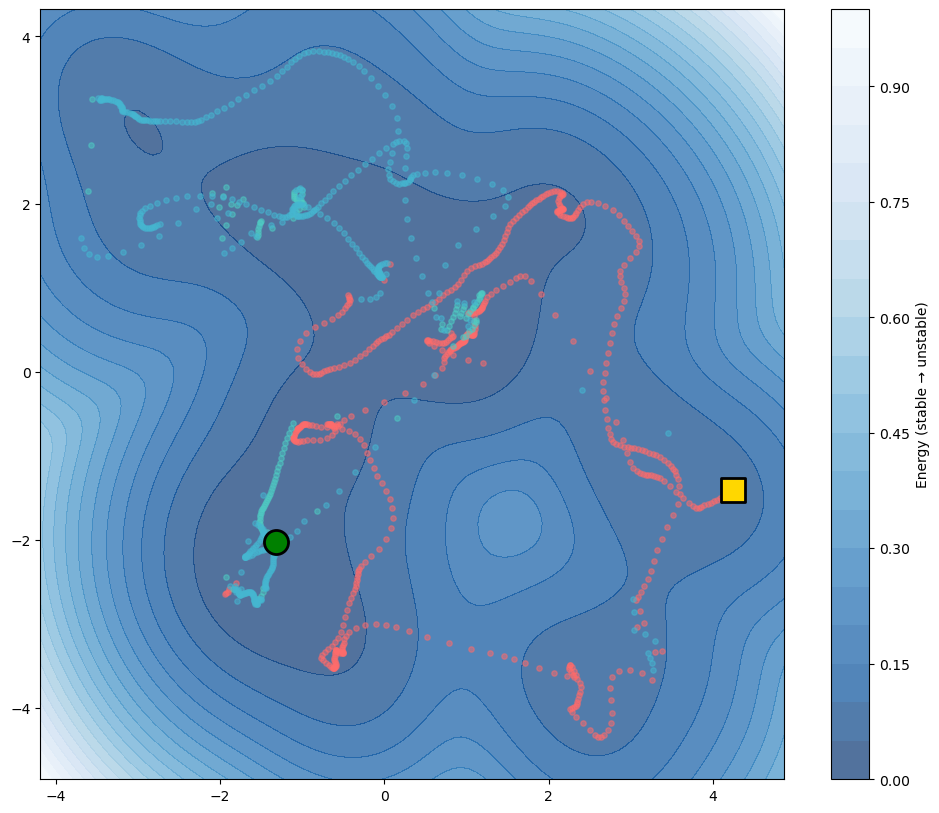

In [14]:
# ============================================================================
# FINAL ANALYSIS: BEST BOUT MODEL (D=24, VE=93.71%)
# ============================================================================

print("="*80)
print("FINAL ANALYSIS: BEST BOUT MODEL")
print("="*80)

import numpy as np
from scipy.io import loadmat
import ssm
import time
import json
import warnings
import matplotlib.pyplot as plt
import gc
import pickle
from scipy.stats import gaussian_kde

warnings.filterwarnings('ignore')
%matplotlib inline

# ----------------------------------------------------------------------------
# 1. DEFINE FUNCTIONS
# ----------------------------------------------------------------------------
def fit_rslds_simple(data_T, K, D_latent, seed, max_iters=80):
    """Simplified fitting - no complex early stopping"""
    np.random.seed(seed)
    start_time = time.time()
    
    model = ssm.SLDS(
        data_T.shape[1], K, D_latent,
        transitions="recurrent_only",
        dynamics="diagonal_gaussian",
        emissions="gaussian_orthog",
        single_subspace=True
    )
    
    model.initialize(data_T)
    
    # Single fit call with fixed iterations
    elbos, posterior = model.fit(
        data_T,
        method="laplace_em",
        variational_posterior="structured_meanfield",
        num_iters=max_iters,
        initialize=False
    )
    
    continuous_states = posterior.mean_continuous_states[0]
    discrete_probs = posterior.mean_discrete_states[0]
    discrete_states = np.argmax(discrete_probs, axis=1)
    
    return model, discrete_states, continuous_states, elbos, time.time() - start_time

def variance_explained_simple(model, continuous_states):
    """Variance explained - simple version"""
    C = model.emissions.Cs[0]
    log_noise_var = model.emissions.inv_etas[0]
    noise_var = np.exp(log_noise_var)
    
    T, D = continuous_states.shape
    x_centered = continuous_states - continuous_states.mean(axis=0)
    cov_x = (x_centered.T @ x_centered) / (T - 1)
    latent_var = np.diag(cov_x)
    
    total_latent_var = np.sum(latent_var)
    total_noise_var = np.sum(noise_var)
    var_exp_global = total_latent_var / (total_latent_var + total_noise_var + 1e-10)
    var_exp_per_latent = latent_var / (np.sum(latent_var) + 1e-10)
    
    return var_exp_per_latent, var_exp_global

print("✓ Functions defined")

# ----------------------------------------------------------------------------
# 2. LOAD DATA (if not already loaded)
# ----------------------------------------------------------------------------
# If you already have individual_bouts from the previous run, skip this
# Otherwise, load the data:

try:
    # Check if individual_bouts exists
    if 'individual_bouts' not in dir():
        print("Loading data...")
        data_path = r'C:\Users\LENOVO\OneDrive\Documents\URECA_codes\data\rawdata_combined.mat'
        mat_raw = loadmat(data_path)
        mpo = mat_raw['MPO_cno']
        struct0 = mpo[0, 0][0, 0]
        trace = struct0['trace'].astype(np.float32)
        label = struct0['label'].flatten()
        
        # Find all aggression bouts
        aggression_bouts = []
        in_bout = False
        bout_start = 0
        
        for i in range(len(label)):
            if label[i] == 14 and not in_bout:
                bout_start = i
                in_bout = True
            elif label[i] != 14 and in_bout:
                bout_end = i - 1
                if bout_start >= 500 and bout_end + 500 < len(label):
                    aggression_bouts.append((bout_start, bout_end))
                in_bout = False
        
        if in_bout and bout_start + 500 < len(label):
            aggression_bouts.append((bout_start, len(label) - 1))
        
        print(f"Found {len(aggression_bouts)} aggression bouts")
        
        # Extract all bouts
        individual_bouts = []
        for bout_idx, (bs, be) in enumerate(aggression_bouts):
            start_idx = bs - 500
            end_idx = be + 500
            bout_window = trace[start_idx:end_idx, :].copy()
            
            # Z-score normalize each bout
            means = bout_window.mean(axis=0, keepdims=True)
            stds = bout_window.std(axis=0, keepdims=True)
            stds[stds == 0] = 1
            bout_window_norm = (bout_window - means) / stds
            
            individual_bouts.append(bout_window_norm)
            print(f"  Bout {bout_idx+1}: {bout_window_norm.shape}")
        
        # Clean up
        del mat_raw, mpo, trace, label
        gc.collect()
        
    print(f"✓ Loaded {len(individual_bouts)} bouts")

except Exception as e:
    print(f"Error loading data: {e}")
    
# ----------------------------------------------------------------------------
# 3. BEST BOUT: Bout 3 (index 2) with VE=93.71%
# ----------------------------------------------------------------------------
best_bout_idx = 2  # Bout 3 (0-indexed)
best_bout_data = individual_bouts[best_bout_idx]

print(f"\nBest bout data shape: {best_bout_data.shape}")
print(f"Bout {best_bout_idx+1}: 500 pre + 880 attack + 500 post = 1880 samples")

# ----------------------------------------------------------------------------
# 4. FIT FINAL MODEL ON BEST BOUT
# ----------------------------------------------------------------------------
print("\n" + "="*80)
print("FITTING FINAL MODEL ON BEST BOUT (Bout 3)")
print("="*80)

K_final = 3
D_final = 24
SEED = 532
MAX_ITERS = 200

print(f"K={K_final}, D={D_final}, seed={SEED}, max_iters={MAX_ITERS}")
print("Fitting...")

model_final, disc_final, cont_final, elbos_final, ft_final = fit_rslds_simple(
    best_bout_data, K_final, D_final, SEED, max_iters=MAX_ITERS
)

ve_latent, ve_global = variance_explained_simple(model_final, cont_final)

print(f"\n✓ Model fitted in {ft_final:.1f}s")
print(f"  Final ELBO: {elbos_final[-1]:.0f}")
print(f"  Variance Explained: {ve_global*100:.2f}%")

# Check if target met
if ve_global >= 0.90:
    print(f"  ✓✓✓ TARGET MET! ({ve_global*100:.2f}% ≥ 90%)")
else:
    print(f"  ⚠ Target not met ({ve_global*100:.2f}% < 90%)")

# ----------------------------------------------------------------------------
# 5. SAVE MODEL
# ----------------------------------------------------------------------------
with open('best_bout_model_bout3.pkl', 'wb') as f:
    pickle.dump({
        'model': model_final,
        'continuous_states': cont_final,
        'discrete_states': disc_final,
        'elbos': elbos_final,
        'K': K_final,
        'D': D_final,
        'seed': SEED,
        've_global': ve_global,
        've_per_latent': ve_latent.tolist(),
        'bout': best_bout_idx + 1,
        'fit_time': ft_final
    }, f)

print(f"\n✓ Model saved to: best_bout_model_bout3.pkl")

# ----------------------------------------------------------------------------
# 6. ENERGY LANDSCAPE
# ----------------------------------------------------------------------------
print("\n" + "="*80)
print("GENERATING ENERGY LANDSCAPE")
print("="*80)

fig, ax = plt.subplots(figsize=(12, 10))

x1 = cont_final[:, 0]
x2 = cont_final[:, 1]

# Create grid
n_grid = 100
x1_grid = np.linspace(x1.min() - 0.5, x1.max() + 0.5, n_grid)
x2_grid = np.linspace(x2.min() - 0.5, x2.max() + 0.5, n_grid)
X1, X2 = np.meshgrid(x1_grid, x2_grid)

# KDE and energy
kde = gaussian_kde(np.vstack([x1, x2]))
positions = np.vstack([X1.ravel(), X2.ravel()])
density = kde(positions).reshape(X1.shape)
energy = -np.log(density + 1e-10)
energy = (energy - energy.min()) / (energy.max() - energy.min())

# Plot
contour = ax.contourf(X1, X2, energy, levels=20, cmap='Blues_r', alpha=0.7)
cbar = plt.colorbar(contour, ax=ax, label='Energy (stable → unstable)')

# Trajectory colored by state
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
for state in range(K_final):
    mask = disc_final == state
    if np.any(mask):
        ax.scatter(cont_final[mask, 0], cont_final[mask, 1],
                   c=colors[state], s=15, alpha=0.5, label=f'State {state}')

# Key time points
pre_end = 500
during_end = 500 + 880  # bout duration

ax.scatter(cont_final[0, 0], cont_final[0, 1], marker='o', s=300,
           c='green', edgecolors='black', linewidth=2, label='Start (Pre)', zorder=10)
ax.scatter(cont_final[pre_end, 0], cont_final[pre_end, 1], marker='s', s=300,
           c='gold', edgecolors='black', linewidth=2, label='Aggression Start', zorder=10)
ax.scatter(cont_final[during_end, 0], cont_final[during_end, 1], marker='^', s=300,
           c='orange', edgecolors='black', linewidth=2, label='Aggression End', zorder=10)
ax.scatter(cont_final[-1, 0], cont_final[-1, 1], marker='D', s=300,
           c='purple', edgecolors='black', linewidth=2, label='End (Post)', zorder=10)

# Trajectory line
ax.plot(cont_final[:, 0], cont_final[:, 1], 'k-', alpha=0.3, linewidth=1.5)

ax.set_xlabel('Latent Dimension 1', fontsize=14)
ax.set_ylabel('Latent Dimension 2', fontsize=14)
ax.set_title(f'Energy Landscape - Best Bout (Bout 3, VE={ve_global*100:.2f}%)', fontsize=16)
ax.legend(loc='best', fontsize=10)
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('energy_landscape_best_bout.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Energy landscape saved: energy_landscape_best_bout.png")

# ----------------------------------------------------------------------------
# 7. TIME CONSTANT ANALYSIS
# ----------------------------------------------------------------------------
print("\n" + "="*80)
print("TIME CONSTANT ANALYSIS")
print("="*80)

from scipy.optimize import curve_fit

def exponential_decay(t, A, tau, C):
    return A * np.exp(-t / tau) + C

pre_end = 500
during_end = 500 + 880

time_constants = []
r2_values = []

for dim in range(D_final):
    latent = cont_final[:, dim]
    
    # Find peak during aggression
    peak_region = latent[pre_end:during_end]
    if len(peak_region) > 0:
        peak_idx = pre_end + np.argmax(np.abs(peak_region))
        decay_region = latent[peak_idx:]
        t_decay = np.arange(len(decay_region))
        
        if len(decay_region) > 20:
            try:
                p0 = [decay_region[0], 50, decay_region[-1]]
                params, _ = curve_fit(exponential_decay, t_decay, decay_region,
                                      p0=p0, maxfev=5000)
                tau = params[1]
                
                # R-squared
                fitted = exponential_decay(t_decay, *params)
                ss_res = np.sum((decay_region - fitted)**2)
                ss_tot = np.sum((decay_region - np.mean(decay_region))**2)
                r2 = 1 - (ss_res / ss_tot)
                
                time_constants.append(tau)
                r2_values.append(r2)
            except:
                time_constants.append(0)
                r2_values.append(0)
        else:
            time_constants.append(0)
            r2_values.append(0)
    else:
        time_constants.append(0)
        r2_values.append(0)

# Find attractor dimensions (τ > 100 samples = >3.3 seconds)
attractor_dims = [(i, tau, r2) for i, (tau, r2) in enumerate(zip(time_constants, r2_values)) 
                  if tau > 100 and r2 > 0.5]

print(f"\nDimensions with persistent dynamics (τ > 100 samples, R² > 0.5):")
if attractor_dims:
    for dim, tau, r2 in sorted(attractor_dims, key=lambda x: x[1], reverse=True)[:5]:
        print(f"  Dim {dim}: τ={tau:.1f} samples ({tau/30:.2f}s), R²={r2:.3f}")
else:
    print("  No dimensions with strong persistence found")

# Show top 5 time constants overall
top_tau = sorted([(i, tau, r2) for i, (tau, r2) in enumerate(zip(time_constants, r2_values)) 
                  if tau > 0], key=lambda x: x[1], reverse=True)[:5]

print(f"\nTop 5 time constants overall:")
for dim, tau, r2 in top_tau:
    print(f"  Dim {dim}: τ={tau:.1f} samples ({tau/30:.2f}s), R²={r2:.3f}")

# ----------------------------------------------------------------------------
# 8. PER-LATENT VE DISTRIBUTION
# ----------------------------------------------------------------------------
print("\n" + "="*80)
print("PER-LATENT VARIANCE EXPLAINED")
print("="*80)

sorted_dims = np.argsort(ve_latent)[::-1]
print(f"Top 5 latent dimensions by VE contribution:")
for i, dim in enumerate(sorted_dims[:5]):
    print(f"  Dim {dim}: {ve_latent[dim]*100:.2f}%")

print(f"\nBottom 5 latent dimensions by VE contribution:")
for i, dim in enumerate(sorted_dims[-5:]):
    print(f"  Dim {dim}: {ve_latent[dim]*100:.2f}%")

# ----------------------------------------------------------------------------
# 9. SUMMARY
# ----------------------------------------------------------------------------
print("\n" + "="*80)
print("FINAL SUMMARY - BEST BOUT MODEL")
print("="*80)

print(f"\nModel Configuration:")
print(f"  K (discrete states) = {K_final}")
print(f"  D (latent dimensions) = {D_final}")
print(f"  Seed = {SEED}")
print(f"  Max iterations = {MAX_ITERS}")

print(f"\nData:")
print(f"  Bout = {best_bout_idx + 1}")
print(f"  Time points = {best_bout_data.shape[0]}")
print(f"  Neurons = {best_bout_data.shape[1]}")

print(f"\nResults:")
print(f"  Variance Explained = {ve_global*100:.2f}%")
print(f"  Final ELBO = {elbos_final[-1]:.0f}")
print(f"  Fit time = {ft_final:.1f}s")

print(f"\nFiles saved:")
print(f"  - best_bout_model_bout3.pkl")
print(f"  - energy_landscape_best_bout.png")

print("\n" + "="*80)
print("✓ ANALYSIS COMPLETE")
print("="*80)
